# Preprocessing dan Text Vectorization


## 1. Membaca Data

In [2]:
import pandas as pd
from pathlib import Path

data = pd.DataFrame({
    'teks': [
        'Saya sangat senang dengan pelayanan toko ini karena pegawainya ramah dan barang yang dibeli berkualitas baik. '
        'Pengiriman barang sangat lambat dan kemasannya rusak ketika sampai di rumah. '
        'Saya membeli sebuah buku melalui aplikasi kemarin sore.'
        'Produk ini memiliki harga terjangkau dan kualitas yang sangat memuaskan. '
        'Saya kecewa karena barang yang diterima tidak sesuai dengan gambar pada aplikasi.'
    ],
    'label_asli': [0]
})

data['label'] = data['label_asli'].map({
    0: 'Positif',
    1: 'Negatif'
})

data.head()

,teks,label_asli,label
0,Saya sangat senang dengan pelayanan toko ini k...,0,Positif


## 2. Pemeriksaan Data

In [3]:
print('Ukuran data:', data.shape)
print('Nilai kosong:')
print(data.isna().sum())
print('Jumlah label:')
print(data['label'].value_counts())

Ukuran data: (1, 3)
Nilai kosong:
teks          0
label_asli    0
label         0
dtype: int64
Jumlah label:
label
Positif    1
Name: count, dtype: int64


## 3. Case Folding dan Pembersihan Tanda Baca

In [4]:
import re

data['huruf_kecil'] = data['teks'].str.lower()

data['bersih'] = data['huruf_kecil'].str.replace(
    r'[^a-z0-9\s]', ' ', regex=True
)

data['bersih'] = data['bersih'].str.replace(
    r'\s+', ' ', regex=True
).str.strip()

data[['teks', 'bersih']].head()

,teks,bersih
0,Saya sangat senang dengan pelayanan toko ini k...,saya sangat senang dengan pelayanan toko ini k...


## 4. Tokenisasi

In [5]:
contoh = data.loc[0, 'bersih']
token = contoh.split()

print('Teks:', contoh)
print('Token:', token)
print('Jumlah token:', len(token))

Teks: saya sangat senang dengan pelayanan toko ini karena pegawainya ramah dan barang yang dibeli berkualitas baik pengiriman barang sangat lambat dan kemasannya rusak ketika sampai di rumah saya membeli sebuah buku melalui aplikasi kemarin sore produk ini memiliki harga terjangkau dan kualitas yang sangat memuaskan saya kecewa karena barang yang diterima tidak sesuai dengan gambar pada aplikasi
Token: ['saya', 'sangat', 'senang', 'dengan', 'pelayanan', 'toko', 'ini', 'karena', 'pegawainya', 'ramah', 'dan', 'barang', 'yang', 'dibeli', 'berkualitas', 'baik', 'pengiriman', 'barang', 'sangat', 'lambat', 'dan', 'kemasannya', 'rusak', 'ketika', 'sampai', 'di', 'rumah', 'saya', 'membeli', 'sebuah', 'buku', 'melalui', 'aplikasi', 'kemarin', 'sore', 'produk', 'ini', 'memiliki', 'harga', 'terjangkau', 'dan', 'kualitas', 'yang', 'sangat', 'memuaskan', 'saya', 'kecewa', 'karena', 'barang', 'yang', 'diterima', 'tidak', 'sesuai', 'dengan', 'gambar', 'pada', 'aplikasi']
Jumlah token: 57


## 5. Penghapusan Stopwords

In [6]:
!pip install Sastrawi

from Sastrawi.StopWordRemover.StopWordRemoverFactory import (
    StopWordRemoverFactory
)

stopwords = set(StopWordRemoverFactory().get_stop_words())
stopwords = stopwords - {'tidak', 'bukan', 'jangan', 'belum'}

token_penting = []
for kata in token:
    if kata not in stopwords:
        token_penting.append(kata)

print(token_penting)
print('Jumlah token:', len(token), '->', len(token_penting))

['sangat', 'senang', 'pelayanan', 'toko', 'pegawainya', 'ramah', 'barang', 'dibeli', 'berkualitas', 'baik', 'pengiriman', 'barang', 'sangat', 'lambat', 'kemasannya', 'rusak', 'rumah', 'membeli', 'sebuah', 'buku', 'melalui', 'aplikasi', 'kemarin', 'sore', 'produk', 'memiliki', 'harga', 'terjangkau', 'kualitas', 'sangat', 'memuaskan', 'kecewa', 'barang', 'diterima', 'tidak', 'sesuai', 'gambar', 'aplikasi']
Jumlah token: 57 -> 38


## 6. Stemming

In [7]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

stemmer = StemmerFactory().create_stemmer()
hasil_stem = [stemmer.stem(kata) for kata in token_penting]

print('Sebelum:', token_penting)
print('Sesudah:', hasil_stem)

Sebelum: ['sangat', 'senang', 'pelayanan', 'toko', 'pegawainya', 'ramah', 'barang', 'dibeli', 'berkualitas', 'baik', 'pengiriman', 'barang', 'sangat', 'lambat', 'kemasannya', 'rusak', 'rumah', 'membeli', 'sebuah', 'buku', 'melalui', 'aplikasi', 'kemarin', 'sore', 'produk', 'memiliki', 'harga', 'terjangkau', 'kualitas', 'sangat', 'memuaskan', 'kecewa', 'barang', 'diterima', 'tidak', 'sesuai', 'gambar', 'aplikasi']
Sesudah: ['sangat', 'senang', 'layan', 'toko', 'pegawai', 'ramah', 'barang', 'beli', 'kualitas', 'baik', 'kirim', 'barang', 'sangat', 'lambat', 'kemas', 'rusak', 'rumah', 'beli', 'buah', 'buku', 'lalu', 'aplikasi', 'kemarin', 'sore', 'produk', 'milik', 'harga', 'jangkau', 'kualitas', 'sangat', 'muas', 'kecewa', 'barang', 'terima', 'tidak', 'sesuai', 'gambar', 'aplikasi']


## 7. Frekuensi Kata

In [8]:
from collections import Counter
import matplotlib.pyplot as plt

semua_kata = ' '.join(data['bersih']).split()
frekuensi = Counter(
    kata for kata in semua_kata if kata not in stopwords
)

print(frekuensi.most_common(10))

[('sangat', 3), ('barang', 3), ('aplikasi', 2), ('senang', 1), ('pelayanan', 1), ('toko', 1), ('pegawainya', 1), ('ramah', 1), ('dibeli', 1), ('berkualitas', 1)]


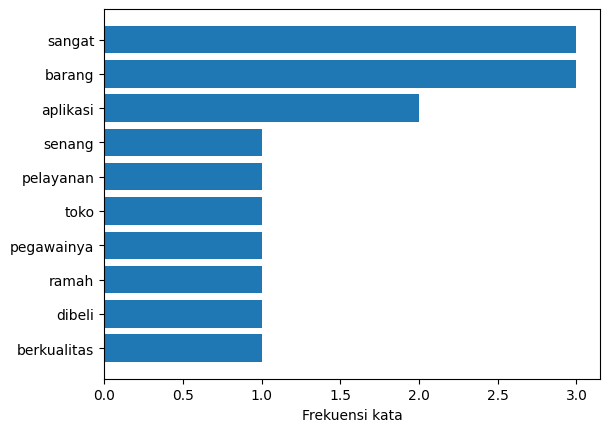

In [9]:
kata, jumlah = zip(*frekuensi.most_common(10))

plt.barh(kata, jumlah)
plt.xlabel('Frekuensi kata')
plt.gca().invert_yaxis()
plt.show()

## 8. Bag of Words dengan CountVectorizer

In [10]:
from sklearn.feature_extraction.text import CountVectorizer

dokumen = data['bersih']

count = CountVectorizer()
matriks_count = count.fit_transform(dokumen)

print('Ukuran matriks BoW:', matriks_count.shape)

pd.DataFrame(
    matriks_count.toarray(),
    columns=count.get_feature_names_out()
)

Ukuran matriks BoW: (1, 43)


,aplikasi,baik,barang,berkualitas,buku,dan,dengan,di,dibeli,diterima,...,sangat,saya,sebuah,senang,sesuai,sore,terjangkau,tidak,toko,yang
0,2,1,3,1,1,3,2,1,1,1,...,3,3,1,1,1,1,1,1,1,3


## 9. TF-IDF

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()
matriks_tfidf = tfidf.fit_transform(dokumen)

print('Ukuran matriks TF-IDF:', matriks_tfidf.shape)

pd.DataFrame(
    matriks_tfidf.toarray(),
    columns=tfidf.get_feature_names_out()
).round(2)

Ukuran matriks TF-IDF: (1, 43)


,aplikasi,baik,barang,berkualitas,buku,dan,dengan,di,dibeli,diterima,...,sangat,saya,sebuah,senang,sesuai,sore,terjangkau,tidak,toko,yang
0,0.21,0.1,0.31,0.1,0.1,0.31,0.21,0.1,0.1,0.1,...,0.31,0.31,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.31
